In [1]:
from dask.distributed import Client

client = Client("tcp://127.0.0.1:40983")
client

<Client: 'tcp://127.0.0.1:40983' processes=8 threads=32, memory=503.70 GiB>

In [2]:
import numpy as np
import xarray as xr
import os.path as op
import gsw

from xgcm.grid import Grid
from scipy.optimize import curve_fit

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
ddir = "/storage/tartar/takaya/bruno/basilisk/"

In [4]:
H = xr.open_zarr(op.join(ddir,"SW/48/bathy.zarr")).H

for pp in range(6,9):
    if pp == 6:
        ds = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                            ).isel(level=slice(None,None)
                                  ).chunk({"time":1,"level":-1,"y":128,"x":256})
    else:
        tmp = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                            ).isel(time=slice(1,None),
                                   level=slice(None,None)
                                  ).chunk({"time":1,"level":-1,"y":128,"x":256}
                                         )
        time = tmp.time.data + ds.time[-1].data
        tmp = tmp.reset_index("time", drop=False)
        tmp = tmp.reset_coords("time", drop=True)
        tmp.coords["time"] = ("time", time)
        ds = xr.concat([ds, tmp], "time")
        tmp.close()
    
ds

<xarray.Dataset> Size: 317GB
Dimensions:  (time: 630, level: 5, y: 2048, x: 4096)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    h        (time, level, y, x) float32 106GB dask.array<chunksize=(1, 5, 128, 256), meta=np.ndarray>
    u.x      (time, level, y, x) float32 106GB dask.array<chunksize=(1, 5, 128, 256), meta=np.ndarray>
    u.y      (time, level, y, x) float32 106GB dask.array<chunksize=(1, 5, 128, 256), meta=np.ndarray>

In [5]:
dsb = xr.open_zarr(op.join(ddir,"SW/48/mean/UVh.zarr")
                  ).chunk({"level":1,"y":128,"x":256})
dsb2z = xr.open_zarr(op.join(ddir,"SW/48/b-to-Z.zarr")
                   ).chunk({"time":4,"Z":1})
dsb2zb = xr.open_zarr(op.join(ddir,"SW/48/mean/b-to-Z.zarr"))
dsu2z = xr.open_zarr(op.join(ddir,"SW/48/UyVx_b-to-Z.zarr")
                   ).chunk({"time":4,"Z":1})
dsu2zb = xr.open_zarr(op.join(ddir,"SW/48/mean/UyVx_b-to-Z.zarr"))

# hbar = ds.h.mean(["time"])
hbar = dsb.hbar
maskh = xr.DataArray(np.ma.masked_values(hbar,0.).mask,
                     dims=hbar.dims, 
                     coords=hbar.coords
                    ).load()
llo, lla = np.meshgrid(ds.x, ds.y)
xxG = xr.DataArray(gsw.distance(llo, lla), dims=["y","xG"],
                  coords={"y":ds.y.data,
                          "xG":.5*(ds.x.data[1:]+ds.x.data[:-1])}
                 )
yyG = xr.DataArray(gsw.distance(llo, lla, axis=0), dims=["yG","x"],
                  coords={"yG":.5*(ds.y.data[1:]+ds.y.data[:-1]),
                          "x":ds.x.data}
                 )
cori = gsw.f(ds.y)

dsb, dsb2z, dsb2zb

(<xarray.Dataset> Size: 671MB
 Dimensions:  (level: 4, y: 2048, x: 4096)
 Coordinates:
   * level    (level) float32 16B 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
 Data variables:
     hbar     (level, y, x) float32 134MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
     ubar     (level, y, x) float32 134MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
     uhat     (level, y, x) float32 134MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
     vbar     (level, y, x) float32 134MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
     vhat     (level, y, x) float32 134MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>,
 <xarray.Dataset> Size: 592GB
 Dimensions:  (time: 630, y: 2048, x: 4096, Z: 7)
 Coordinates:
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
   * y        (y) float32 8kB 9.01 9.0

Fitted Equation: y = 0.0118 * e^(0.2000 * x) + -0.0334


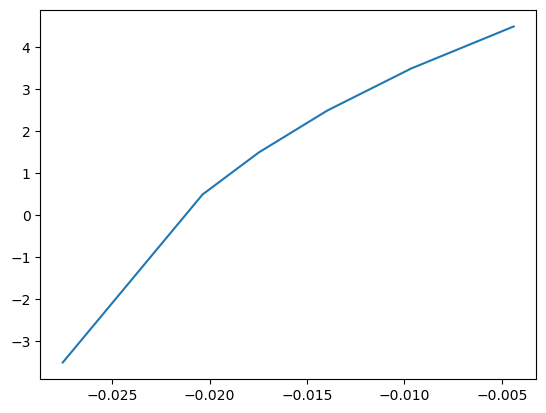

<xgcm.Grid>
X Axis (not periodic, padding='extend'):
  * center   x --> inner
  * inner    xG --> center
Y Axis (not periodic, padding='extend'):
  * center   y --> inner
  * inner    yG --> center
Z Axis (not periodic, padding='extend'):
  * center   level --> outer
  * outer    lp1 --> center <xgcm.Grid>
X Axis (not periodic, padding='extend'):
  * center   x --> inner
  * inner    xG --> center
Y Axis (not periodic, padding='extend'):
  * center   y --> inner
  * inner    yG --> center
Z Axis (not periodic, padding='extend'):
  * center   level


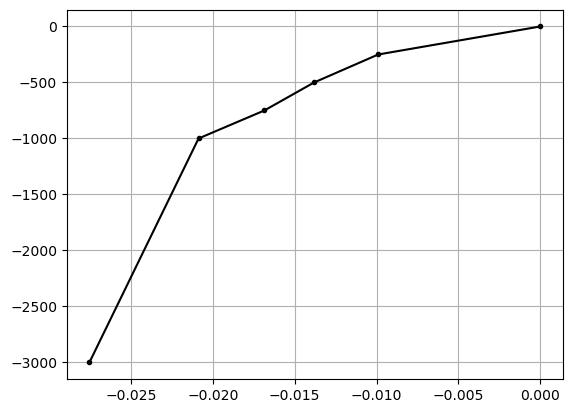

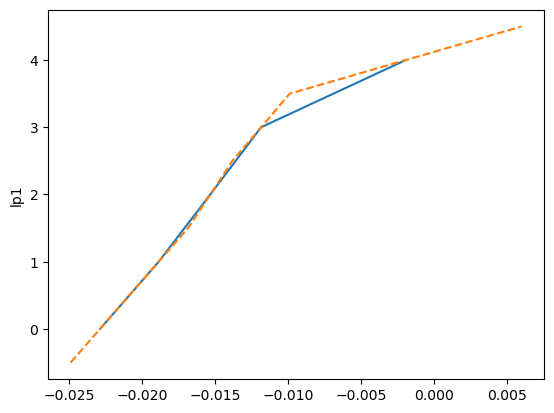

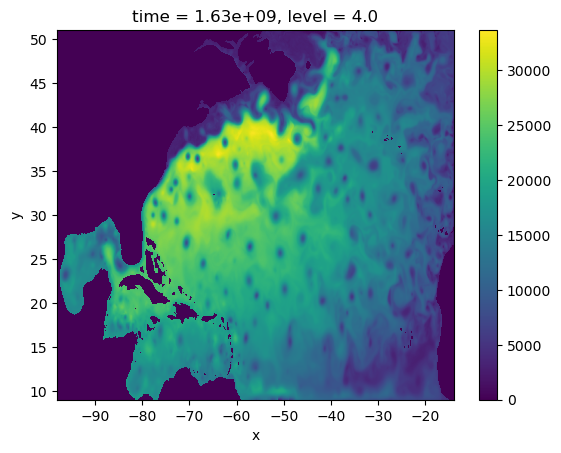

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 264.02 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


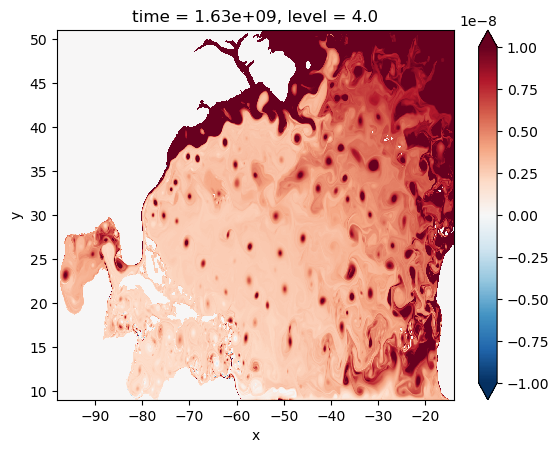

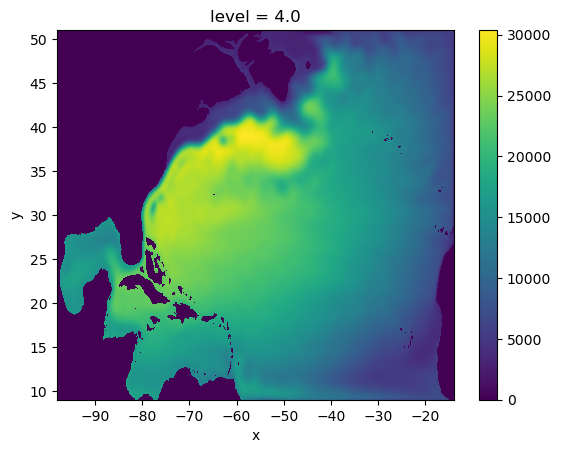

(<xarray.DataArray (time: 630, level: 4, y: 2048, x: 4096)> Size: 169GB
 dask.array<rechunk-merge, shape=(630, 4, 2048, 4096), dtype=float64, chunksize=(4, 4, 128, 256), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
   * level    (level) float32 16B 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01,
 <xarray.DataArray (level: 4, y: 2048, x: 4096)> Size: 268MB
 dask.array<where, shape=(4, 2048, 4096), dtype=float64, chunksize=(1, 128, 256), chunktype=numpy.ndarray>
 Coordinates:
   * level    (level) float32 16B 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01,
 <xarray.DataArray (level: 4, y: 2048, x: 4096)> Size: 268MB
 dask.array<where, shape=(4, 2048, 4096), dtype=fl

In [6]:
rho0 = 1e3
drho = np.array([2.13, 1.72, 1.41, 1.01,])
rho = xr.DataArray(drho + rho0, 
                   dims="lp1",
                   coords={"lp1":np.array([0.5,1.5,2.5,3.5])}
                  )

b = -9.8*(rho - rho0) / rho0

# B = 0.2
# def exp_func(x, a, c):
#     return a * np.exp(B * x) + c

# initial_guess = [1, -1e-2]
# popt, pcov = curve_fit(exp_func, b[1:].lp1.values, b[1:].values, 
#                        p0=initial_guess)

# # 3. Extract parameters
# A, C = popt
# print(f"Fitted Equation: y = {A:.4f} * e^({B:.4f} * x) + {C:.4f}")
# plt.plot(A*np.exp(B*np.array([0.5,1.5,2.5,3.5,4.5]))+C, 
#          np.array([0.5,1.5,2.5,3.5,4.5]))
# plt.show()

# bu = xr.DataArray(np.concatenate((b.data,
#                     np.array([A*np.exp(B*(4.5))+C,]) 
#                    )), dims="lu", 
#                    coords={"lu":np.array([0.5,1.5,2.5,3.5,4.5])}
#                   )
B = 0.2
def exp_func(x, a, c):
    return a * np.exp(B * x) + c

initial_guess = [1, -1e-2]
popt, pcov = curve_fit(exp_func, b.lp1.values, b.values, p0=initial_guess)

# 3. Extract parameters
A, C = popt
print(f"Fitted Equation: y = {A:.4f} * e^({B:.4f} * x) + {C:.4f}")
plt.plot(A*np.exp(B*np.array([-3.5,0.5,1.5,2.5,3.5,4.5]))+C, 
         np.array([-3.5,0.5,1.5,2.5,3.5,4.5]))
plt.show()

# bp1 = xr.DataArray(np.concatenate((np.concatenate((np.array([A*np.exp(B*(-3.5))+C,]),b.data)),
#                     np.array([A*np.exp(B*(4.5))+C,]) 
#                    )), dims="lp1", 
#                    coords={"lp1":np.array([-.5,0.5,1.5,2.5,3.5,4.5])}
#                   )
bp1 = xr.DataArray(np.concatenate((np.concatenate((np.array([A*np.exp(B*(-3.5))+C,]),b.data)),
                    np.array([0.,]) 
                   )), dims="lp1", 
                   coords={"lp1":np.array([-.5,0.5,1.5,2.5,3.5,4.5])}
                  )

# ds["b"] = bu
ds["bp1"] = bp1
ds.coords["yG"] = ("yG",.5*(ds.y.data[1:]+ds.y.data[:-1]))
ds.coords["xG"] = ("xG",.5*(ds.x.data[1:]+ds.x.data[:-1]))
# grid = Grid(ds, padding={'X': 'extend', 'Y': 'extend', "Z": "extend"}, 
#             autoparse_metadata=False,
#             coords={"X": {"center": "x", "inner": "xG"},
#                     "Y": {"center": "y", "inner": "yG"},
#                     "Z": {"center": "level", "right": "lu"}
#                    })
grid = Grid(ds, padding={'X': 'extend', 'Y': 'extend', "Z": "extend"}, 
            autoparse_metadata=False,
            coords={"X": {"center": "x", "inner": "xG"},
                    "Y": {"center": "y", "inner": "yG"},
                    "Z": {"center": "level", "outer": "lp1"}
                   })
dsb.coords["yG"] = ("yG",.5*(dsb.y.data[1:]+dsb.y.data[:-1]))
dsb.coords["xG"] = ("xG",.5*(dsb.x.data[1:]+dsb.x.data[:-1]))
gridb = Grid(dsb, padding={'X': 'extend', 'Y': 'extend', "Z": "extend"}, 
             autoparse_metadata=False,
             coords={"X": {"center": "x", "inner": "xG"},
                     "Y": {"center": "y", "inner": "yG"},
                     "Z": {"center": "level",}
                    })
print(grid, gridb)

fig, ax = plt.subplots()
ax.plot(ds.bp1, -np.array([3000,1000,750,500,250,0]), "k.-")
ax.grid(True)
plt.show()

v_x = (grid.interp(grid.diff((ds["u.y"]*ds.h).fillna(0.).chunk({"x":-1}), 
                             "X", padding="extend"
                            ) / xxG, 
                   "X", padding="extend"
                  ) / ds.h
      ).fillna(0.)
u_y = (grid.interp(grid.diff((ds["u.x"]*ds.h).fillna(0.).chunk({"y":-1}), 
                             "Y", padding="extend"
                            ) / yyG, 
                   "Y", padding="extend"
                  ) / ds.h
      ).fillna(0.)

ssh = xr.open_zarr(op.join(ddir,"SW/48/SSH.zarr")).ssh
dsz = xr.open_zarr(op.join(ddir,"SW/48/Z.zarr")
                  ).Z.transpose("time","level","y","x"
                               ).to_dataset(name="Z")
dsz["Zl"] = xr.open_zarr(op.join(ddir,"SW/48/Zl.zarr")
                        ).Zl.transpose("time","lp1","y","x")
dsm = xr.open_zarr(op.join(ddir,"SW/48/Montgomery.zarr"))
# b = grid.interp(ds2.bp1,"Z",padding="extend").isel(level=slice(None,-1))
# b = xr.concat([xr.ones_like(dsm.m.isel(level=slice(None,-1))) * b, 
#                xr.DataArray((b.isel(level=-2).data 
#                              - (grid.diff(dsm.m.chunk({"level":-1}),
#                                           "Z",padding="extend"
#                                          ).isel(lp1=-2)
#                                 / dsz.Zl.isel(lp1=-1)
#                                ).data[:,np.newaxis,:,:]
#                             ), dims=["time","level","y","x"],
#                             coords={"time":ds2.time.data,
#                                     "level":np.array([4.,]),
#                                     "y":ds2.y.data,"x":ds2.x.data}
#                            )
#               ], "level").sortby("level")
_b = grid.interp(ds.bp1,"Z",padding="extend"
                ).isel(level=slice(1,-1))
# tmp = (b.isel(level=-2).data
#        - (grid.diff(dsm.m.chunk({"level":-1}),
#                     "Z",padding="extend"
#                    ).isel(lp1=-2)
#           / dsz.Zl.isel(lp1=-1)
#          ).mean(["time","y","x"],skipna=True).data
#       ).compute()
rho0 = 1e3; g = 9.8
dr = np.array([.41,.31,.40,1.01])
gp = np.concatenate((g*dr/rho0, np.array([10.,])))
b = xr.concat([_b.copy(), 
               # xr.DataArray(np.array([tmp,]), dims=["level"],
               #              coords={"level":np.array([ds2.level[-1].values,])}
               #             )
               xr.DataArray(np.array([_b.isel(level=-1).data+gp[-2]]), 
                            dims=["level"],
                            coords={"level":np.array([ds.level[-1].values,])}
                           )
              ], "level"
             ).sortby("level")
b = xr.concat([xr.DataArray(np.array([_b.isel(level=0).data-gp[0]]), 
                            dims=["level"],
                            coords={"level":np.array([ds.level[0].values,])}
                           ),
               b], "level"
             ).sortby("level")

# ds["Z"] = dsz.Z.transpose("time","level","y","x").chunk({"level":-1})
Zp1 = xr.concat([dsz.Zl, xr.DataArray(ssh.data[:,np.newaxis,:,:],
                                    dims=dsz.Zl.dims, 
                                    coords={"lp1":np.array([4.5,])})
                ], "lp1").sortby("lp1")
ds["Zp1"] = Zp1.transpose("time","lp1","y","x").chunk({"lp1":-1})

# bp1 = (xr.ones_like(ds2.Zp1) * ds.bp1).isel(lp1=slice(None,-1))
# bp1 = xr.concat([bp1, 
#                  xr.DataArray((bp1.isel(lp1=-1)
#                                + 2*(b.isel(level=-1)-ds.bp1.isel(lp1=-2)
#                                    )
#                               ).data[:,np.newaxis,:,:],
#                               dims=["time","lp1","y","x"], 
#                               coords={"time":b.time.data,
#                                       "lp1":np.array([ds.lp1[-1].values,]),
#                                       "y":b.y.data,"x":b.x.data})
#                 ], "lp1").sortby("lp1")
_bp1 = ds.bp1.isel(lp1=slice(1,-1))
bp1 = xr.concat([_bp1.copy(), 
                 xr.DataArray(np.array([_bp1.isel(lp1=-1)
                                        + 2*(b.isel(level=-1)-_bp1.isel(lp1=-1)
                                            ).data,
                                       ]),
                              dims=["lp1"], 
                              coords={"lp1":np.array([ds.lp1[-1].values,]),})
                ], "lp1").sortby("lp1")
bp1 = xr.concat([xr.DataArray(np.array([_bp1.isel(lp1=0)
                                        + 2*(b.isel(level=0)-_bp1.isel(lp1=0)
                                            ).data,
                                       ]),
                              dims=["lp1"], 
                              coords={"lp1":np.array([ds.lp1[0].values,]),}), 
                 bp1
                ], "lp1").sortby("lp1")

fig, ax = plt.subplots()
b.plot(ax=ax, y="level")
bp1.plot(ax=ax, y="lp1", ls="--")
plt.show()
# sig = (ds.h
#        / grid.diff(ds.b,"Z",padding="extend")
#       )
sig = (ds.h
       / grid.diff(bp1.chunk({"lp1":-1}),"Z",padding="extend")
      )
sig.isel(time=-1,level=-1).plot(rasterized=True)
plt.show()

Pi = (sig**-1
      * (cori + v_x - u_y)
     ).isel(level=slice(1,None)).where(~maskh, 0.).chunk({"time":4,"y":128,"x":256})
Pi.isel(time=-1,level=-1).plot(vmax=1e-8, rasterized=True)
plt.show()

sigb = (dsb.hbar 
        / grid.diff(bp1.chunk({"lp1":-1}),"Z",padding="extend")
       )
sigb.isel(level=-1).plot(rasterized=True)
plt.show()

# vb_x = (xxG**-1 * dsb.vbar.isel(level=-1).diff("x").dropna("x").data
#        ).interp(xG=dsb.x.data).chunk({"y":128,"xG":256})
# ub_y = (yyG**-1 * dsb.ubar.isel(level=-1).diff("y").dropna("y").data
#        ).interp(yG=dsb.y.data).chunk({"yG":128,"x":256})
# vb_x = (gridb.interp(gridb.diff((dsb.ubar*dsb.hbar).chunk({"x":-1}), 
#                                 "X", padding="extend"
#                                ) / xxG, "X", padding="extend"
#                     ) / dsb.hbar
#        ).fillna(0.)
# ub_y = (gridb.interp(gridb.diff((dsb.vbar*dsb.hbar).chunk({"y":-1}), 
#                                 "Y", padding="extend"
#                                ) / yyG, "Y", padding="extend"
#                     ) / dsb.hbar
#        ).fillna(0.)
vb_x = v_x.mean("time")
ub_y = u_y.mean("time")
bPi = (sigb**-1
       * (cori + vb_x - ub_y)
      ).where(~maskh, 0.)

Pid = Pi - bPi

# vh_x = (xxG**-1 * dsb.vhat.isel(level=-1).diff("x").dropna("x").data
#        ).interp(xG=dsb.x.data).chunk({"y":128,"xG":256})
# uh_y = (yyG**-1 * dsb.uhat.isel(level=-1).diff("y").dropna("y").data
#        ).interp(yG=dsb.y.data).chunk({"yG":128,"x":256})
vh_x = (gridb.interp(gridb.diff((dsb.uhat*dsb.hbar).chunk({"x":-1}), 
                                "X", padding="extend"
                               ) / xxG, "X", padding="extend"
                    ) / dsb.hbar
       )
uh_y = (gridb.interp(gridb.diff((dsb.vhat*dsb.hbar).chunk({"y":-1}), 
                                "Y", padding="extend"
                               ) / yyG, "Y", padding="extend"
                    ) / dsb.hbar
       )
Pih = (sigb**-1
       * (cori + vh_x - uh_y)
      ).where(~maskh, 0.)

Pif = Pi - Pih

Pi, bPi, Pih

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 160.76 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


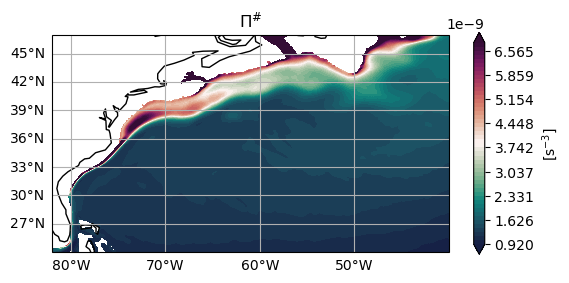

In [7]:
xmax = -40
xmin = -82
ymin = 24
ymax = 47

fig = plt.figure()
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax.coastlines(resolution='110m')
gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

# im = ax.pcolormesh(dsb.x, dsb.y, Pih.isel(level=-2), 
#                   cmap=cmocean.cm.matter,
#                   rasterized=True, vmin=.8e-9, vmax=.7e-8)
im = ax.contourf(dsb.x, dsb.y, Pih.where(Pih>0.).isel(level=-2), 
                 cmap=cmocean.cm.curl,
                 levels=np.linspace(.92e-9,.68e-8,51),
                 extend="both"
                )

# for yyy in yy:
#     ax.plot(xx, np.ones_like(xx)*yyy, "r--", alpha=.9)
# for xxx in xx:
#     ax.plot(np.ones_like(yy)*xxx, yy, "r--", alpha=.9)
# ax.set_aspect("equal")

ax.set_rasterized(True)
# ax.set_xlabel(r"Longitude")
# ax.set_ylabel(r"Latitude")
ax.set_title(r"$\Pi^\#$", fontsize=12)
cb = fig.colorbar(im, ax=ax, shrink=.6)
cb.set_label(r"[s$^{-3}$]")
plt.savefig(op.join(ddir,"Figs/Pihash.pdf"), dpi=200)

In [8]:
# dsz = xr.open_zarr(op.join(ddir,"SW/48/Z.zarr")
#                   ).Z.transpose("time","level","y","x"
#                                ).to_dataset(name="Z")
Zb = dsz.Z.where(dsz.Z<0.).mean("time")
Zb, Pih.where(Pih>0.).sel(x=-60,method="nearest")

(<xarray.DataArray 'Z' (level: 5, y: 2048, x: 4096)> Size: 168MB
 dask.array<mean_agg-aggregate, shape=(5, 2048, 4096), dtype=float32, chunksize=(4, 128, 256), chunktype=numpy.ndarray>
 Coordinates:
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01,
 <xarray.DataArray (level: 4, y: 2048)> Size: 66kB
 dask.array<getitem, shape=(4, 2048), dtype=float64, chunksize=(1, 128), chunktype=numpy.ndarray>
 Coordinates:
   * level    (level) float32 16B 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
     x        float32 4B -60.01)

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 160.74 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


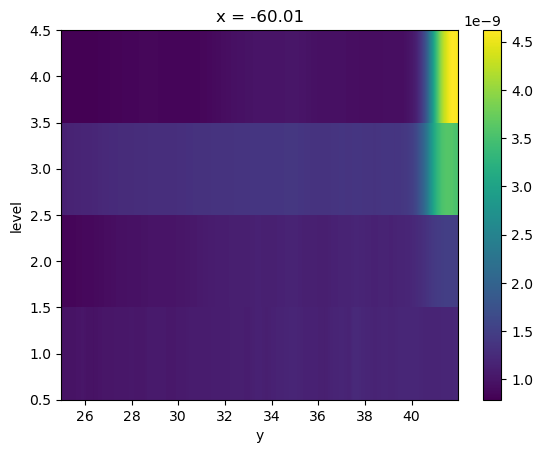

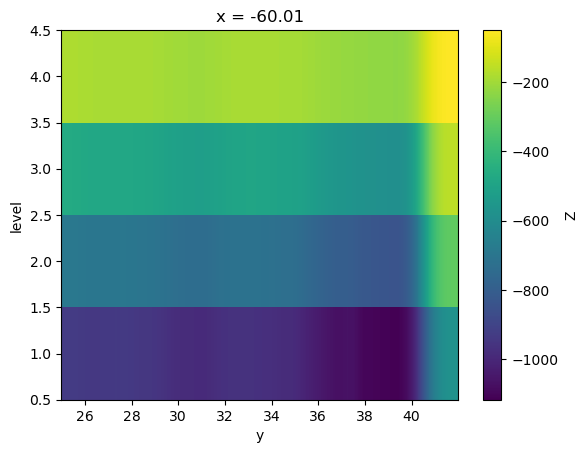

In [65]:
Pih.where(Pih>0.).sel(x=-60,method="nearest"
                     ).sel(y=slice(25,42)).plot(rasterized=True)
plt.show()
Zb.isel(level=slice(1,None)).sel(x=-60,method="nearest"
                                ).sel(y=slice(25,42)).plot(rasterized=True)
plt.show()

In [ ]:
Pih_sel = Pih.sel(x=-60, method="nearest").sel(y=slice(ymin,42))
Zb_sel  = Zb.isel(level=slice(1,None)).sel(x=-60, method="nearest"
                                          ).sel(y=slice(ymin,42))

# Attach Zb as a coordinate so xarray knows the y-axis variable
Pih_sel = Pih_sel.assign_coords(Zb=Zb_sel)

fig, ax = plt.subplots()
Pih_sel.plot.contourf(
    x="y", y="Zb",
    ax=ax, extend="both",
    cmap=cmocean.cm.curl,
    levels=np.linspace(1e-9,4.2e-9,33)
)
ax.set_rasterized(True)
ax.set_title(r"$\Pi^\#$ @ 60$^\circ$W", fontsize=12)
ax.grid(True)
plt.savefig(op.join(ddir,"Figs/Pihash_60W.pdf"), dpi=200)

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 160.74 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [17]:
dsave = Pif.to_dataset(name="Piflat")
dsave["Pip"] = (Pi - Pi.mean("time"))
dsave["Pidagger"] = Pid
print(dsave)
dsave.chunk({"time":4,"y":128,"x":256}
           ).to_zarr(op.join(ddir,"SW/48/TWA/eddyPi/InB.zarr"),
                     mode="w")
dsave.close()

<xarray.Dataset> Size: 507GB
Dimensions:   (time: 630, level: 4, y: 2048, x: 4096)
Coordinates:
  * time      (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * level     (level) float32 16B 1.0 2.0 3.0 4.0
  * y         (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x         (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    Piflat    (time, level, y, x) float64 169GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
    Pip       (time, level, y, x) float64 169GB dask.array<chunksize=(4, 4, 128, 256), meta=np.ndarray>
    Pidagger  (time, level, y, x) float64 169GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 442.19 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [9]:
# Pihat = ((cori + vb_x - ub_y).isel(level=slice(1,None))
#          / sigb).compute()
# Pipp = (Pi - Pihat)
dsPi = xr.open_zarr(op.join(ddir,"SW/48/TWA/eddyPi/InB.zarr"))
Pipp = dsPi.Pidagger

dspp = xr.open_zarr(op.join(ddir,"SW/48/TWA/Upp.zarr"))
dsave = ((dspp.upp * Pipp * sig).mean("time")
         / sigb).to_dataset(name="uppPpphat")
dsave["vppPpphat"] = ((dspp.vpp * Pipp * sig).mean("time")
                      / sigb)
print(dsave)
dsave.chunk({"y":128,"x":256}
           ).to_zarr(op.join(ddir,"SW/48/TWA/uppPipp.zarr"),
                     mode="w")
dsave.close()

<xarray.Dataset> Size: 537MB
Dimensions:    (level: 4, x: 4096, y: 2048)
Coordinates:
  * level      (level) float32 16B 1.0 2.0 3.0 4.0
  * x          (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
  * y          (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.95 50.97 50.99
Data variables:
    uppPpphat  (level, y, x) float64 268MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
    vppPpphat  (level, y, x) float64 268MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 319.39 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [ ]:
# dsb2z.coords["yG"] = ("yG",.5*(dsb2z.y.data[1:]+dsb2z.y.data[:-1]))
# dsb2z.coords["xG"] = ("xG",.5*(dsb2z.x.data[1:]+dsb2z.x.data[:-1]))
# dsb2zb.coords["yG"] = ("yG",.5*(dsb2z.y.data[1:]+dsb2z.y.data[:-1]))
# dsb2zb.coords["xG"] = ("xG",.5*(dsb2z.x.data[1:]+dsb2z.x.data[:-1]))

# grid = Grid(dsb2z, periodic=None, autoparse_metadata=False,
#             coords={"X": {"center": "x", "inner": "xG"},
#                     "Y": {"center": "y", "inner": "yG"},
#                     "Z": {"center": "Z"}
#                    })
# gridb = Grid(dsb2zb, periodic=None, autoparse_metadata=False,
#             coords={"X": {"center": "x", "inner": "xG"},
#                     "Y": {"center": "y", "inner": "yG"},
#                     "Z": {"center": "Z"}
#                    })
# print(grid)

# v_x = grid.interp(grid.diff(dsb2z.u.chunk({"x":-1}), 
#                             "X", boundary="extend"
#                            ) / xxG, "X", boundary="extend")
# u_y = grid.interp(grid.diff(dsb2z.v.chunk({"y":-1}), 
#                             "Y", boundary="extend"
#                            ) / yyG, "Y", boundary="extend")
Pi = (dsb2z.sig**-1
      * (cori + dsu2z.v_x - dsu2z.u_y)
     ).chunk({"time":4,"y":128,"x":256})

# vb_x = grid.interp(grid.diff(dsb2zb.ub.chunk({"x":-1}), 
#                              "X", boundary="extend"
#                             ) / xxG, "X", boundary="extend")
# ub_y = grid.interp(grid.diff(dsb2zb.vb.chunk({"y":-1}), 
#                              "Y", boundary="extend"
#                             ) / yyG, "Y", boundary="extend")
bPi = (dsb2zb.sigb**-1
       * (cori + dsu2zb.vb_x - dsu2zb.ub_y)
      ).chunk({"y":128,"x":256}) 
Pid = Pi - bPi

Pi, Pid

In [8]:
dsave = (Pi - Pi.mean("time",skipna=True)).to_dataset(name="Pip")
dsave["Pidagger"] = Pid
print(dsave)
dsave.chunk({"time":4,"y":128,"x":256}
           ).to_zarr(op.join(ddir,"SW/48/TWA/eddyPi/InZ_grad1st.zarr"),
                     mode="w")
dsave.close()

<xarray.Dataset> Size: 592GB
Dimensions:   (time: 630, x: 4096, y: 2048, Z: 7)
Coordinates:
  * time      (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * x         (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
  * y         (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * Z         (Z) int64 56B -875 -750 -625 -500 -375 -250 -125
Data variables:
    Pip       (time, y, x, Z) float64 296GB dask.array<chunksize=(4, 128, 256, 1), meta=np.ndarray>
    Pidagger  (time, y, x, Z) float64 296GB dask.array<chunksize=(4, 128, 256, 1), meta=np.ndarray>


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 34.37 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [9]:
dsPiz = xr.open_zarr(op.join(ddir,"SW/48/TWA/eddyPi/b-to-Z.zarr"))
# dsz = xr.open_zarr(op.join(ddir,"SW/TWA/eddyPi/InZ.zarr"))
dsz = xr.open_zarr(op.join(ddir,"SW/48/TWA/eddyPi/InZ_grad1st.zarr"))
dsz

<xarray.Dataset> Size: 592GB
Dimensions:   (time: 630, y: 2048, x: 4096, Z: 7)
Coordinates:
  * time      (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * y         (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x         (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
  * Z         (Z) int64 56B -875 -750 -625 -500 -375 -250 -125
Data variables:
    Pidagger  (time, y, x, Z) float64 296GB dask.array<chunksize=(4, 128, 256, 1), meta=np.ndarray>
    Pip       (time, y, x, Z) float64 296GB dask.array<chunksize=(4, 128, 256, 1), meta=np.ndarray>

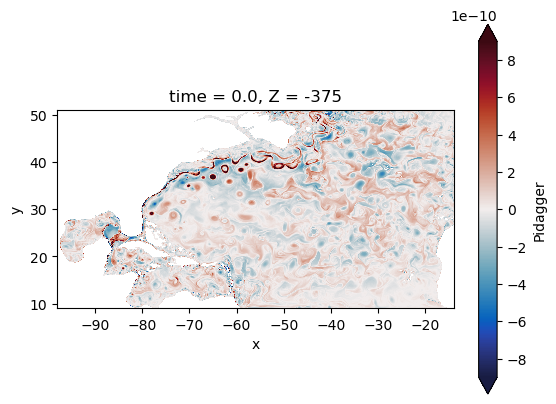

In [10]:
fig, ax = plt.subplots()
dsz.Pidagger.isel(time=0,Z=-3).plot(ax=ax, vmax=9e-10, cmap=cmocean.cm.balance, rasterized=True)
ax.set_aspect("equal")

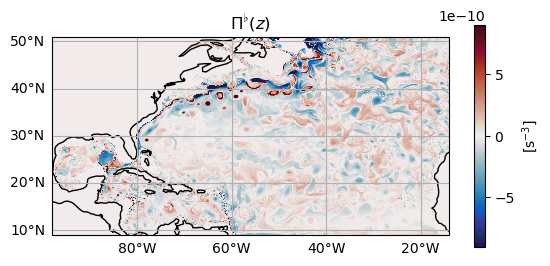

In [11]:
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([ds.x.min(), ds.x.max(), 
               ds.y.min(), ds.y.max()], 
              crs=ccrs.PlateCarree())
ax.coastlines(resolution='110m')
gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

im = ax.pcolormesh(ds.x, ds.y, dsPiz.Piflat.isel(time=0,Z=-3), 
                   vmax=9e-10, vmin=-9e-10,
                  cmap=cmocean.cm.balance,
                  rasterized=True)

ax.set_xlabel(r"Longitude")
ax.set_ylabel(r"Latitude")
ax.set_title(r"$\Pi^\flat(z)$", fontsize=12)
cb = fig.colorbar(im, ax=ax, shrink=.6)
cb.set_label(r"[s$^{-3}$]")
plt.savefig(op.join(ddir,"Figs/PVflat.pdf"))

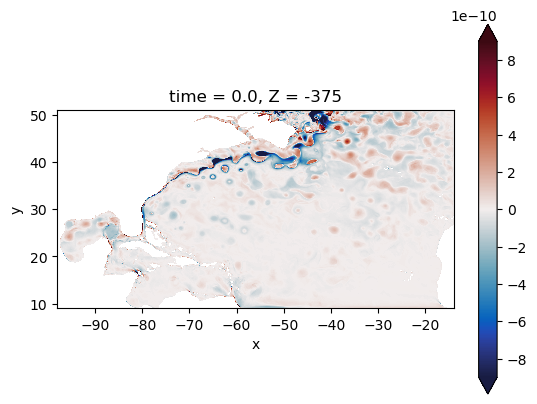

In [12]:
fig, ax = plt.subplots()
(dsPiz.Piflat - dsz.Pidagger).isel(time=0,Z=-3).plot(ax=ax, vmax=9e-10, 
                                                     cmap=cmocean.cm.balance, 
                                                     rasterized=True)
ax.set_aspect("equal")

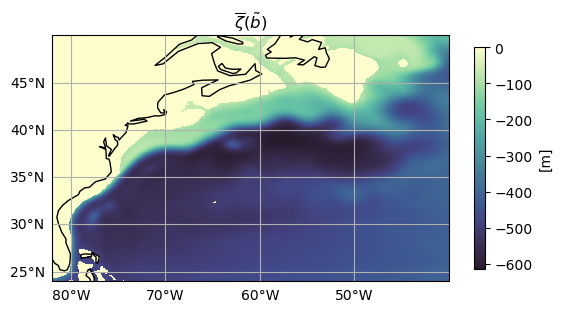

In [16]:
xmax = -40
xmin = -82
ymin = 24
ymax = 50

fig = plt.figure()
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax.coastlines(resolution='110m')
gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

im = ax.pcolormesh(dsb.x, dsb.y, dsz.Z.isel(level=-2).mean("time"), 
                  cmap=cmocean.cm.deep_r,
                  rasterized=True)

# for yyy in yy:
#     ax.plot(xx, np.ones_like(xx)*yyy, "r--", alpha=.9)
# for xxx in xx:
#     ax.plot(np.ones_like(yy)*xxx, yy, "r--", alpha=.9)
# ax.set_aspect("equal")

# ax.set_xlabel(r"Longitude")
# ax.set_ylabel(r"Latitude")
ax.set_title(r"$\overline{\zeta}(\tilde{b})$", fontsize=12)
cb = fig.colorbar(im, ax=ax, shrink=.6)
cb.set_label(r"[m]")
plt.savefig(op.join(ddir,"Figs/Zbar_2nd.pdf"))

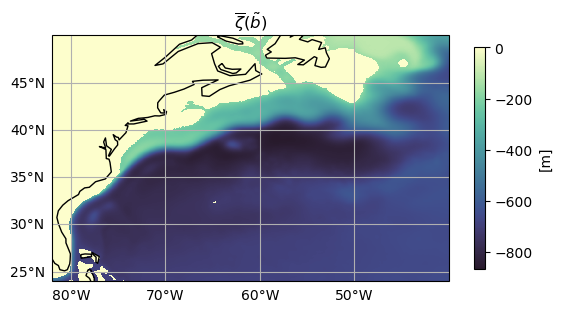

In [15]:
xmax = -40
xmin = -82
ymin = 24
ymax = 50

fig = plt.figure()
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax.coastlines(resolution='110m')
gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

im = ax.pcolormesh(dsb.x, dsb.y, dsz.Z.isel(level=-3).mean("time"), 
                  cmap=cmocean.cm.deep_r,
                  rasterized=True)

# for yyy in yy:
#     ax.plot(xx, np.ones_like(xx)*yyy, "r--", alpha=.9)
# for xxx in xx:
#     ax.plot(np.ones_like(yy)*xxx, yy, "r--", alpha=.9)
# ax.set_aspect("equal")

# ax.set_xlabel(r"Longitude")
# ax.set_ylabel(r"Latitude")
ax.set_title(r"$\overline{\zeta}(\tilde{b})$", fontsize=12)
cb = fig.colorbar(im, ax=ax, shrink=.6)
cb.set_label(r"[m]")
plt.savefig(op.join(ddir,"Figs/Zbar_3rd.pdf"))